In [2]:
from PIL import Image
from pathlib import Path
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv("faces.csv")
A = df.to_numpy()

In [4]:
def show_image(row, shape=(127,127)):
    img = row.reshape(shape)
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.show()

In [5]:
#SVD
U, S, Vt = np.linalg.svd(A, full_matrices=False)

Number of singular values: 3278
Rank: 3278


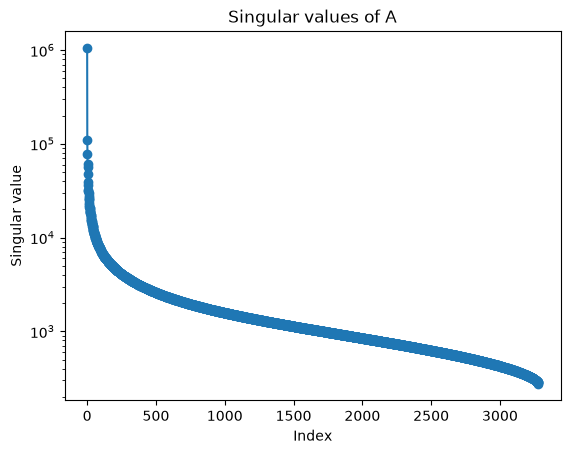

In [6]:
print(f"Number of singular values: {len(S)}")
rank = np.linalg.matrix_rank(A)
print(f"Rank: {rank}")

plt.figure()
plt.plot(S, marker="o")
plt.xlabel("Index")
plt.ylabel("Singular value")
plt.title("Singular values of A")
plt.yscale("log")
plt.show()

In [7]:
#trimming to a low rank of k
k = 1
U_p = U[:,:k].copy()
S_p = S[:k].copy()
Vt_p = Vt[:k,:].copy()

#reassemble A prime from the trimmed matrices
A_p = (U_p * S_p) @ Vt_p
print("Aprime dimensions: ", A_p.shape)
print("A dimensions: ",A.shape)

Aprime dimensions:  (3278, 16129)
A dimensions:  (3278, 16129)


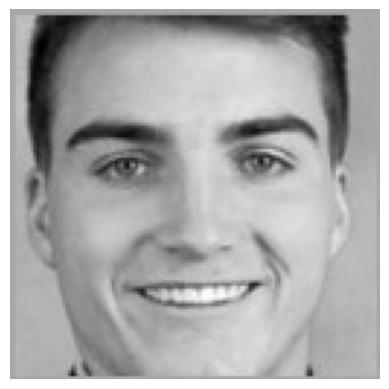

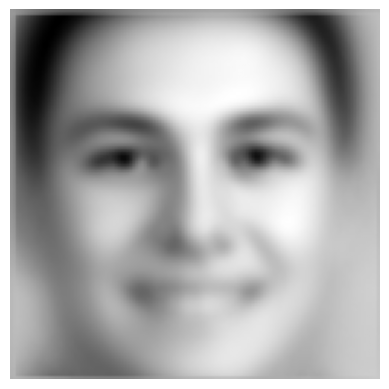

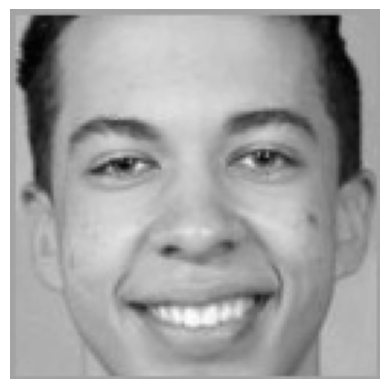

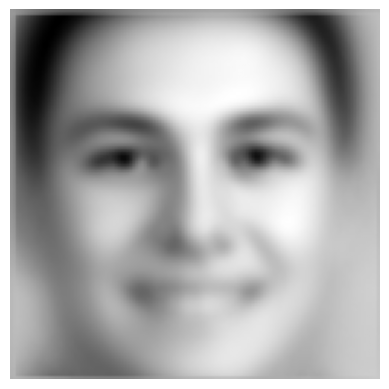

In [8]:
#compare before and after lowrank reduction
show_image(A[1])
show_image(A_p[1])
show_image(A[0])
show_image(A_p[0])